# Harvard EEG Database (HEEDB v4.1) — data report and onboarding plan next to TUH

📄 **[PDF version](heedb_data_report.pdf)**

The Harvard Electroencephalography Database (HEEDB, Brain Data Science Platform, credentialed
access) holds clinical EEG from Boston-area hospitals in BIDS format, with per-session **EEG
report findings** and per-patient **health records** (ICD-10 diagnoses, ATC medications). Our
brain-age and normal/abnormal models are trained on TUH (TUAB + TUEG cohorts). This notebook
measures HEEDB with **the same analytics we ran on TUH**, so the two corpora can be compared
column for column, and ends with the recommended data preparation and the plan to onboard
HEEDB into the TUH pipeline (`docs/heedb_onboarding_plan.md`).

Everything is read **in place** through the BDSP S3 access point: the metadata CSVs, every EDF
header (S3 byte-range reads, `dataset_maker/heedb_index.py`) and two-minute signal excerpts of
a stratified sample (`labram/eval/heedb_analysis.py`). No HEEDB recording is copied for this
report. **DUA:** HEEDB data and derivatives stay private (never `s3://eeg-data-public`); this
notebook shows only aggregates, no identifiers, and applies small-cell suppression: counts of 1–9
individuals are shown as `<10` and no statistic is computed on fewer than 10
(`heedb_analysis.suppress_small`).

**Contents.** 1 Sources and layout · 2 Recording length · 3 Demographics · 4 EEG reports ·
5 Health records, aligned with the TUH clinical sheet · 6 Cohorts for brain age ·
7 The EEG signal: headers · 8 The EEG signal: content and line noise ·
9 Recommended data preparation and filtering · 10 Plan: onboarding HEEDB like TUH ·
11 Findings · 12 Export to PDF.

In [1]:
import os
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO_ROOT))

import pickle

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from dataset_maker import heedb_index as hx
from dataset_maker import tuh_clinical
from labram.data.tuh_metadata import TUH_CHANNELS
from labram.eval import heedb_analysis as ha
from labram.eval import preprocessing_qc as qc
from labram.eval.age_plots import assert_max_columns, numbered_table, panel_labels

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
ROOT = os.environ.get("HEEDB_ROOT", hx.DEFAULT_ROOT)
C_H, C_A, C_E = "#1f6fb4", "#d1495b", "#66a182"      # HEEDB, TUAB, TUEG


def finish(fig, axes=None):
    fig.tight_layout()
    if axes is not None and len(np.ravel(axes)) > 1:
        panel_labels(axes)
    assert_max_columns(fig)
    plt.show()


# HEEDB: one row per EDF (sessions without an EDF keep one row).
idx = pd.read_parquet(f"{ROOT}/index/heedb_index.parquet")
ses = idx.drop_duplicates(["subject", "session"]).copy()           # one row per session
main = ses[ses["site"].isin(hx.MAIN_SITES)]
ar = main[main["routine"] & main["adult"]]                         # the download set
ar_edf = idx[idx["site"].isin(hx.MAIN_SITES) & idx["routine"] & idx["adult"] & idx["key"].notna()]
hdr = ar_edf[ar_edf["n_signals"].notna()]                           # EDFs with a scanned header

# TUH: recording index + NEDC clinical sheet (tuh_clinical.join_index).
tuh = ha.load_tuh(cache="/data/datasets/EEG-public/TUH_EEG/index/tuh_clinical_index.parquet")
tuab = tuh[tuh["cohort"] == "TUAB"].assign(abnormal_report=lambda d: d["abnormal"].astype("boolean"))
tueg = tuh[tuh["cohort"] == "TUEG"]
tuh_adult = tuh[tuh["age"].between(*hx.ADULT_AGE)]
print(f"HEEDB: {len(idx):,} index rows, {len(ses):,} sessions, {len(ar):,} adult routine sessions, "
      f"{len(hdr):,} headers scanned | TUH: {len(tuh):,} recordings")

HEEDB: 341,084 index rows, 341,079 sessions, 72,124 adult routine sessions, 72,118 headers scanned | TUH: 71,348 recordings


## 1. Sources and layout

HEEDB is organised by **site** (one hospital or partner each) and, within a site, by
**service**: *Routine* (outpatient/inpatient EEG of 20–60 minutes, the study type of TUAB and
most of TUEG), *LTM* (long-term ICU/inpatient monitoring, hours to days), *EMU* (epilepsy
monitoring unit) and *OR* (intra-operative). Table 1.1 lists the sources the index joins;
`dataset_maker/heedb_index.py::build_index` aligns them on `(site, patient, session)`.

### Table 1.1. HEEDB sources joined into the index

One row per source table: what it holds and at which level (session = one EEG study,
patient = all of a patient's records). TUH counterpart = the table that carries the same
information in our TUH pipeline.

In [2]:
t11 = pd.DataFrame([
    ("eeg-metadata/‹site›_eeg_metadata.csv", "session", "start, duration, service, age, sex, date of death",
     "EDF header (age, sex, date) + folder"),
    ("bids/‹site›/sub-*/ses-*/eeg/*_eeg.edf", "recording", "signal, 10-20 + auxiliary channels",
     "TUEG / TUAB EDF"),
    ("*_channels.tsv, *_eeg.json, *_annotations.csv", "recording", "channel types, sfreq, events",
     "— (EDF header only)"),
    ("HEEDB_Metadata/‹site›_EEG_reports_findings.csv", "session", "normal/abnormal + ~45 findings",
     "TUAB folder label; NEDC sheet `abnormal due to`, FIRDA…LPD"),
    ("HEEDB_Metadata/HEEDB_ICD10_for_Neurology.csv", "patient", "ICD-10 codes in 18 neuro categories",
     "NEDC sheet: 15 Y/N diagnoses"),
    ("HEEDB_Metadata/HEEDB_Medication_ATC.csv", "patient", "ATC level-4 drug groups",
     "NEDC sheet: medication list"),
    ("HEEDB_Metadata/HEEDB_patients.csv", "patient", "sex, mean age, race, visit / ICD / drug counts", "—"),
], columns=["source", "level", "content", "TUH counterpart"]).set_index("source")
numbered_table(t11, "1.1", "HEEDB sources joined into the index")

,level,content,TUH counterpart
source,,,
eeg-metadata/‹site›_eeg_metadata.csv,session,"start, duration, service, age, sex, date of death","EDF header (age, sex, date) + folder"
bids/‹site›/sub-*/ses-*/eeg/*_eeg.edf,recording,"signal, 10-20 + auxiliary channels",TUEG / TUAB EDF
"*_channels.tsv, *_eeg.json, *_annotations.csv",recording,"channel types, sfreq, events",— (EDF header only)
HEEDB_Metadata/‹site›_EEG_reports_findings.csv,session,normal/abnormal + ~45 findings,"TUAB folder label; NEDC sheet `abnormal due to`, FIRDA…LPD"
HEEDB_Metadata/HEEDB_ICD10_for_Neurology.csv,patient,ICD-10 codes in 18 neuro categories,NEDC sheet: 15 Y/N diagnoses
HEEDB_Metadata/HEEDB_Medication_ATC.csv,patient,ATC level-4 drug groups,NEDC sheet: medication list
HEEDB_Metadata/HEEDB_patients.csv,patient,"sex, mean age, race, visit / ICD / drug counts",—


With $d_i$ the duration of session $i$ in seconds (metadata `DurationInSeconds`), the hours of
a group $G$ are

$$
H(G) = \frac{1}{3600}\sum_{i \in G} d_i .
\tag{1.1}
$$

### Table 1.2. Sessions, patients and hours per site and service

All sessions of the metadata tables. `n/a` = the site has no service label (I0002, I0003,
I0008, I0009). Hours by Eq. (1.1); `median_min` = median session length in minutes.

In [3]:
t12 = ha.site_service_table(ses)
numbered_table(ha.suppress_small(t12.set_index(["site", "service"]), ["sessions", "patients"]), "1.2", "Sessions, patients and hours per site and service", precision=0)

### Figure 1.1. Where the HEEDB hours are

(a) Hours per site (Eq. (1.1)), split by service, log scale. (b) Sessions per site, split into
adult routine (the onboarding set, age 18–89, Section 2) and everything else. All sessions.

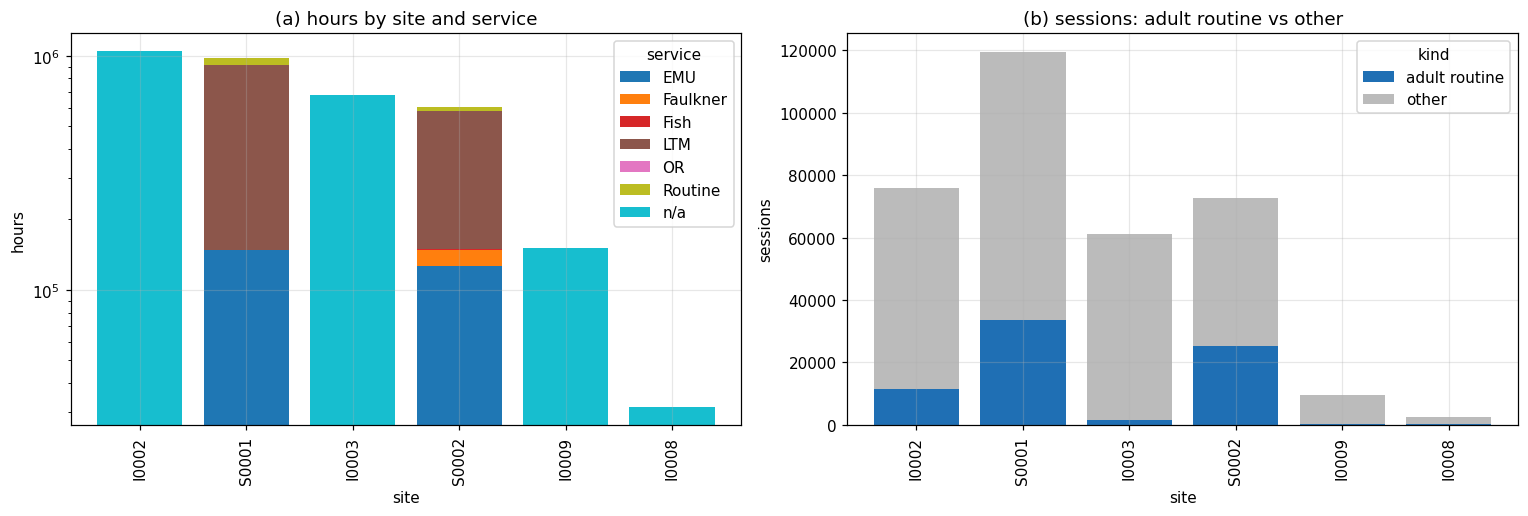

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
piv = t12.pivot_table(index="site", columns="service", values="hours", aggfunc="sum").fillna(0)
piv = piv.loc[piv.sum(axis=1).sort_values(ascending=False).index]
piv.plot.bar(stacked=True, ax=axes[0], width=0.8, colormap="tab10")
axes[0].set_yscale("log"); axes[0].set_ylabel("hours"); axes[0].set_title("hours by site and service")
cnt = ses.assign(kind=np.where(ses["routine"] & ses["adult"], "adult routine", "other")) \
         .groupby(["site", "kind"]).size().unstack(fill_value=0).loc[piv.index]
cnt.plot.bar(stacked=True, ax=axes[1], width=0.8, color=[C_H, "#bbbbbb"])
axes[1].set_ylabel("sessions"); axes[1].set_title("sessions: adult routine vs other")
finish(fig, axes)

## 2. Recording length

TUAB recordings are routine EEGs (median ≈ 20 min); TUEG adds a minority of long-term studies.
HEEDB is dominated **in hours** by LTM/EMU monitoring (Figure 1.1(a)) but **in sessions** routine
studies are the largest single group at S0001/S0002. A routine study is identified by the
service label where the site has one, and otherwise by its length
(`heedb_index.add_routine_flag`):

$$
\text{routine}_i =
\begin{cases}
[\,\text{service}_i = \text{Routine}\,] \wedge [\,10 \le m_i \le 240\,] & \text{site with a service label}\\
[\,15 \le m_i \le 120\,] & \text{otherwise}
\end{cases}
\tag{2.1}
$$

where $m_i = d_i / 60$ is the length in minutes and $[\cdot]$ is 1 when the condition holds.
Quantiles $Q_p$ in Table 2.1 are pandas' linear-interpolation sample quantiles of $m_i$.

### Table 2.1. Recording length (minutes) per group

Columns `p5 … p95` = $Q_p$ of $m_i$; `n` = recordings with a known length. HEEDB rows are
sessions (metadata duration); TUH rows are EDF files (header duration).

In [5]:
groups = {f"HEEDB {s}": main.loc[main["service"].eq(s), "duration_sec"] for s in ["Routine", "LTM", "EMU"]}
groups |= {"HEEDB I0002/I0003 (no service label)": main.loc[main["service"].isna(), "duration_sec"],
           "HEEDB adult routine (Eq. 2.1)": ar["duration_sec"],
           "TUAB": tuab["duration_sec"], "TUEG": tueg["duration_sec"]}
t21 = ha.duration_quantiles(groups)
numbered_table(t21, "2.1", "Recording length (minutes) per group", precision=1)

,p5,p25,p50,p75,p95,n
HEEDB Routine,28.6,45.0,57.4,76.3,102.7,72486.0
HEEDB LTM,35.6,200.6,778.1,1323.6,1497.3,91533.0
HEEDB EMU,53.6,535.8,1290.8,1442.9,1608.6,15543.0
HEEDB I0002/I0003 (no service label),27.6,68.1,741.2,1432.5,1895.1,125727.0
HEEDB adult routine (Eq. 2.1),26.2,42.1,53.5,69.2,97.3,72124.0
TUAB,19.2,20.1,21.1,23.4,28.4,2993.0
TUEG,0.1,4.8,10.0,20.1,56.5,68355.0


### Figure 2.1. Distribution of recording length

(a) HEEDB sessions of the four main sites by service, minutes on a log axis; the dashed lines
mark the 10–240 min routine window of Eq. (2.1). (b) Adult routine HEEDB sessions vs TUAB and
TUEG recordings, 0–120 min, as density.

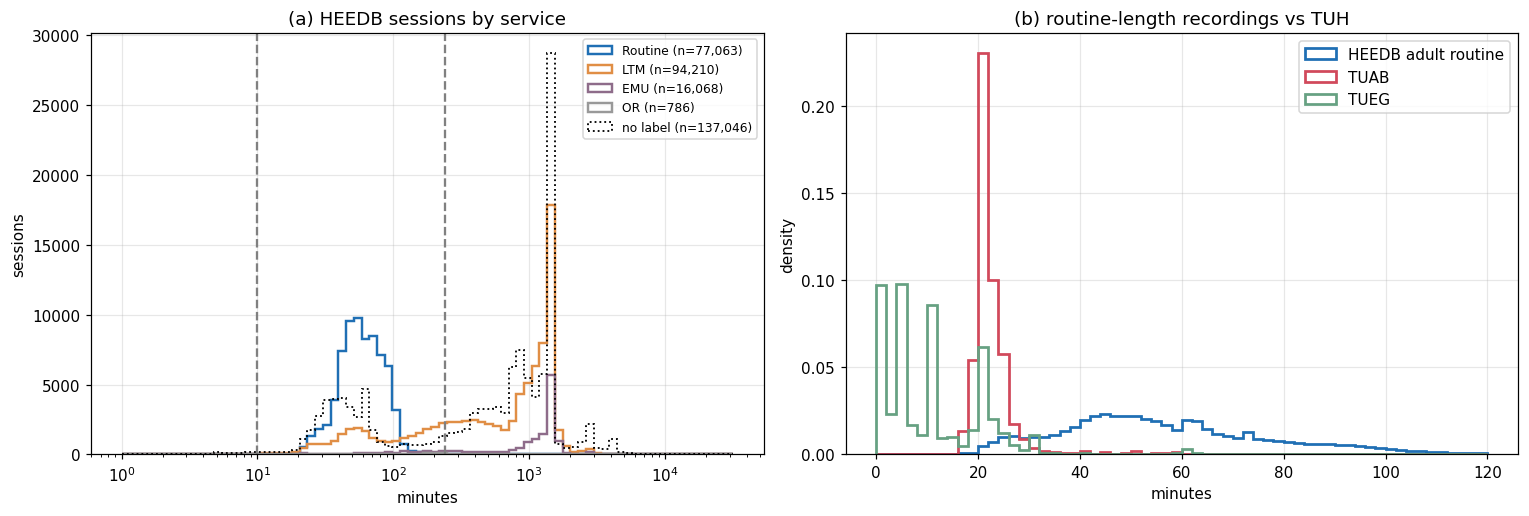

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
bins = np.logspace(0, 4.5, 80)
for s, c in [("Routine", C_H), ("LTM", "#e08e45"), ("EMU", "#8e6c8a"), ("OR", "#999999")]:
    m = main.loc[main["service"].eq(s), "duration_sec"] / 60
    axes[0].hist(m, bins=bins, histtype="step", lw=1.6, color=c, label=f"{s} (n={len(m):,})")
m = main.loc[main["service"].isna(), "duration_sec"] / 60
axes[0].hist(m, bins=bins, histtype="step", lw=1.2, ls=":", color="k", label=f"no label (n={len(m):,})")
for x in hx.ROUTINE_MINUTES:
    axes[0].axvline(x, ls="--", c="gray")
axes[0].set_xscale("log"); axes[0].set_xlabel("minutes"); axes[0].set_ylabel("sessions")
axes[0].legend(fontsize=8); axes[0].set_title("HEEDB sessions by service")
b = np.linspace(0, 120, 61)
for name, d, c in [("HEEDB adult routine", ar, C_H), ("TUAB", tuab, C_A), ("TUEG", tueg, C_E)]:
    axes[1].hist(d["duration_sec"] / 60, bins=b, density=True, histtype="step", lw=1.8, color=c, label=name)
axes[1].set_xlabel("minutes"); axes[1].set_ylabel("density"); axes[1].legend()
axes[1].set_title("routine-length recordings vs TUH")
finish(fig, axes)

## 3. Demographics

Age is the session's `AgeAtVisit` (years, from the hospital record; I0008/I0009 from the date of
birth). TUH's age comes from the EDF header, where TUH redacts ages ≥ 90 (`Age:999`, excluded,
`labram/data/tuh_metadata.py`). HEEDB **does not redact**: it has ages above 89 and a few
impossible values (negative, > 110), which the adult filter (18–89, the same range as
`tuh_clinical.normative_mask`) removes. With $a_i$ the age of recording $i$ and
$\operatorname{dec}(a) = 10\lfloor a/10 \rfloor$ capped at 90, the share of a group $G$ in decade $k$ is

$$
s_k(G) = 100 \cdot \frac{\lvert\{ i \in G : \operatorname{dec}(a_i) = k \}\rvert}{\lvert\{ i \in G : a_i \text{ known}\}\rvert} \;\%.
\tag{3.1}
$$

### Table 3.1. Overview: HEEDB next to TUH

Columns = groups (HEEDB all sessions of the four main sites, HEEDB adult routine, TUAB, TUEG,
TUH adults). `hours` by Eq. (1.1), age in years (mean, sample SD), `female %` among recordings
with a known sex, `with report label %` = share with a normal/abnormal call
(HEEDB report, TUAB folder, NEDC sheet for TUEG), `abnormal %` among those (Eq. (4.1) without
the decade restriction).

In [7]:
t31 = ha.overview({"HEEDB main sites": main, "HEEDB adult routine": ar, "TUAB": tuab, "TUEG": tueg,
                   "TUH adults 18–89": tuh_adult})
numbered_table(t31, "3.1", "Overview: HEEDB next to TUH", precision=1)

,HEEDB main sites,HEEDB adult routine,TUAB,TUEG,TUH adults 18–89
recordings,329093.0,72124.0,2993.0,68355.0,68587.0
patients,125642.0,58226.0,2329.0,13863.0,14069.0
hours,3308974.3,68654.4,1141.0,26028.3,25941.8
median minutes,340.6,53.5,21.1,10.0,10.0
age mean,44.0,54.0,49.1,51.1,52.0
age sd,27.9,19.8,17.4,18.1,17.0
female %,49.2,51.6,53.3,51.9,52.1
with report label %,52.1,50.7,100.0,84.4,84.4
abnormal % (of labelled),72.0,60.3,49.2,56.1,55.7


### Table 3.2. Age decade shares (%)

$s_k(G)$ of Eq. (3.1) per decade (rows) and group (columns). HEEDB all = all main-site sessions,
including children and LTM.

In [8]:
t32 = ha.age_by_decade({"HEEDB all": main["age"], "HEEDB routine (all ages)": main.loc[main["routine"], "age"],
                        "HEEDB adult routine": ar["age"], "TUAB": tuab["age"], "TUEG": tueg["age"]})
numbered_table(t32, "3.2", "Age decade shares (%)", precision=1)

,HEEDB all,HEEDB routine (all ages),HEEDB adult routine,TUAB,TUEG
0–9,17.5,18.2,0.0,0.2,1.1
10–19,9.4,13.7,3.3,2.3,2.2
20–29,8.2,9.3,13.5,14.3,12.1
30–39,7.3,7.4,10.8,13.8,11.9
40–49,7.9,7.9,11.4,19.7,15.3
50–59,12.1,10.9,15.8,20.9,22.5
60–69,15.5,13.3,19.2,15.6,20.0
70–79,13.3,11.5,16.7,8.3,10.4
80–89,7.3,6.5,9.4,5.0,4.6
90+,1.5,1.3,0.0,0.0,0.0


### Table 3.3. Age data quality

Per site: sessions with no age, a negative age, age over 89 (TUH would have redacted them),
over 110 (implausible), and children (under 18). Counts.

In [9]:
def age_quality(a):
    a = pd.to_numeric(a, errors="coerce")
    return {"sessions": len(a), "missing": int(a.isna().sum()), "negative": int((a < 0).sum()),
            "over 89": int((a > 89).sum()), "over 110": int((a > 110).sum()), "under 18": int((a < 18).sum())}
t33 = pd.DataFrame({site: age_quality(g["age"]) for site, g in ses.groupby("site")}).T
numbered_table(ha.suppress_small(t33), "3.3", "Age data quality", precision=0)

,sessions,missing,negative,over 89,over 110,under 18
I0002,75791,0,<10,1959,<10,2275
I0003,61255,201,<10,<10,<10,57191
I0008,2501,0,0,46,0,11
I0009,9485,0,10,102,0,19
S0001,119448,44,0,1746,294,23409
S0002,72599,29,0,1147,96,96


### Figure 3.1. Age distribution

(a) Age of routine sessions (all ages) per main site, 1-year bins, ages over 89 pooled in the last
(90+) bin — I0003 is a paediatric hospital. (b) Adult routine HEEDB sessions vs TUAB and TUEG recordings, density; HEEDB
ages > 89 are already removed by the adult filter.

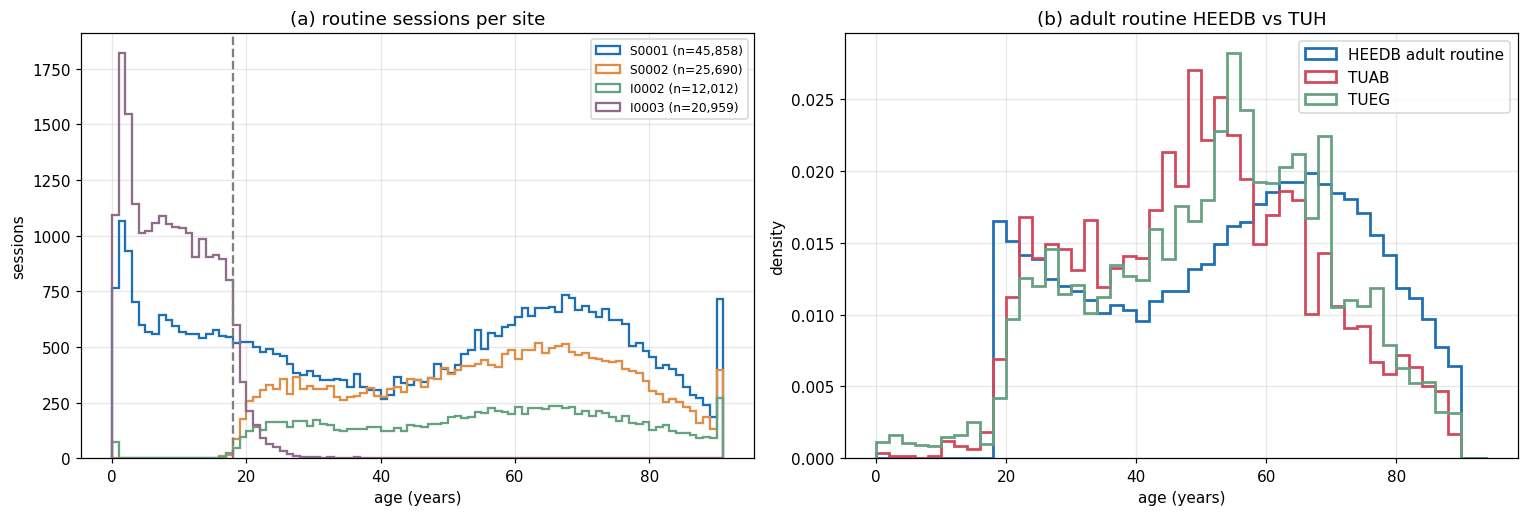

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
b = np.arange(0, 92, 1)
for site, c in zip(hx.MAIN_SITES, ["#1f6fb4", "#e08e45", "#66a182", "#8e6c8a"]):
    # Ages over 89 pooled into one 90+ bin (HIPAA: exact ages above 89 are identifying).
    a = main.loc[main["routine"] & main["site"].eq(site), "age"].clip(upper=90)
    axes[0].hist(a, bins=b, histtype="step", lw=1.5, color=c, label=f"{site} (n={len(a):,})")
axes[0].axvline(18, ls="--", c="gray"); axes[0].set_xlabel("age (years)"); axes[0].set_ylabel("sessions")
axes[0].legend(fontsize=8); axes[0].set_title("routine sessions per site")
b = np.arange(0, 96, 2)
for name, a, c in [("HEEDB adult routine", ar["age"], C_H), ("TUAB", tuab["age"], C_A), ("TUEG", tueg["age"], C_E)]:
    axes[1].hist(a, bins=b, density=True, histtype="step", lw=1.8, color=c, label=name)
axes[1].set_xlabel("age (years)"); axes[1].set_ylabel("density"); axes[1].legend()
axes[1].set_title("adult routine HEEDB vs TUH")
finish(fig, axes)

### Figure 3.2. Sex balance and sessions per patient

(a) Share of female recordings per age decade (Eq. (3.1) groups), adult routine HEEDB vs TUAB
and TUEG. (b) Sessions per patient in each corpus (HEEDB adult routine sessions; TUH
recordings), share of patients, capped at 10.

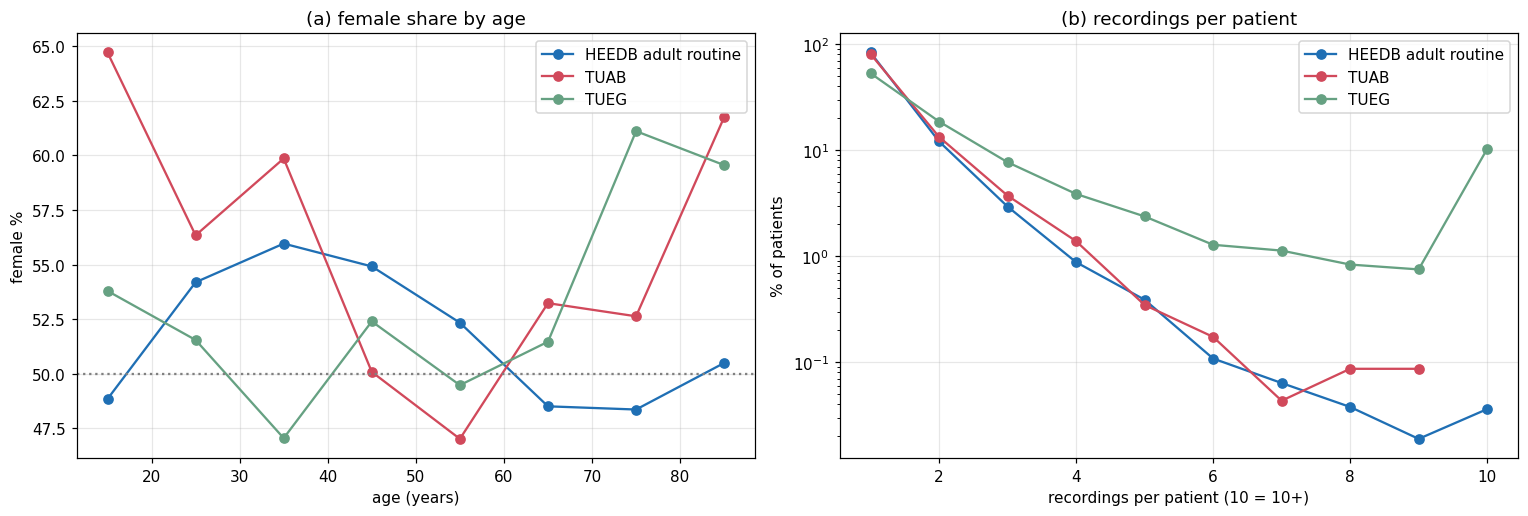

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for name, d, c in [("HEEDB adult routine", ar, C_H), ("TUAB", tuab, C_A), ("TUEG", tueg, C_E)]:
    d = d[d["sex"].isin(["M", "F"]) & d["age"].between(10, 99)]
    f = d.assign(dec=hx.decade(d["age"])).groupby("dec")["sex"].apply(lambda s: 100 * s.eq("F").mean())
    axes[0].plot(f.index + 5, f.values, "o-", color=c, label=name)
    n = d.groupby("subject").size().clip(upper=10).value_counts(normalize=True).sort_index() * 100
    axes[1].plot(n.index, n.values, "o-", color=c, label=name)
axes[0].axhline(50, c="gray", ls=":"); axes[0].set_xlabel("age (years)"); axes[0].set_ylabel("female %")
axes[0].legend(); axes[0].set_title("female share by age")
axes[1].set_xlabel("recordings per patient (10 = 10+)"); axes[1].set_ylabel("% of patients")
axes[1].set_yscale("log"); axes[1].legend(); axes[1].set_title("recordings per patient")
finish(fig, axes)

## 4. EEG reports

Each HEEDB report was processed by BDSP into a normal/abnormal call and ~45 findings. A
finding carries its **provenance**: `report` (stated in the clinical report), `annotation`
(a Persyst/XLTEK machine or technician event in the recording) and `verified` (confirmed by an
expert review). Only `report`/`verified` are comparable to TUH, whose labels come from reports
(TUAB folders, the NEDC sheet's `abnormal due to`), so the index flags `find_<x>` use those two
(`heedb_index.finding_flags`). The abnormal rate of a group $G$ in age decade $k$ is

$$
r_k(G) = 100 \cdot \frac{\lvert\{ i \in G : \operatorname{dec}(a_i) = k,\ y_i = 1 \}\rvert}
{\lvert\{ i \in G : \operatorname{dec}(a_i) = k,\ y_i \text{ known} \}\rvert}\;\%,
\tag{4.1}
$$

with $y_i = 1$ for an abnormal report (TUAB: abnormal folder) and cells of fewer than 30
labelled recordings left empty. A finding's report prevalence is

$$
p(x) = 100 \cdot \frac{\lvert\{ i : \text{find}_x(i) \}\rvert}{\lvert\{ i : y_i \text{ known} \}\rvert}\;\%.
\tag{4.2}
$$

### Table 4.1. Report coverage per site

Main-site sessions: `sessions`, sessions with a report (`with report`), of which normal /
abnormal; the same for adult routine sessions. Counts and the abnormal share (%) of the
reported adult routine sessions.

In [12]:
def coverage(g):
    a = g[g["routine"] & g["adult"]]
    return {"sessions": len(g), "with report": int(g["in_sheet"].sum()),
            "adult routine": len(a), "adult routine with report": int(a["in_sheet"].sum()),
            "normal": int(a["label"].eq("normal").sum()), "abnormal": int(a["label"].eq("abnormal").sum()),
            "abnormal %": 100 * a["label"].eq("abnormal").sum() / max(a["in_sheet"].sum(), 1)}
t41 = pd.DataFrame({s: coverage(g) for s, g in main.groupby("site")}).T
t41.loc["total"] = t41.sum()
t41.loc["total", "abnormal %"] = 100 * t41.loc["total", "abnormal"] / t41.loc["total", "adult routine with report"]
t41 = t41.astype({c: int for c in t41.columns if c != "abnormal %"})
numbered_table(t41, "4.1", "Report coverage per site", precision=1)

,sessions,with report,adult routine,adult routine with report,normal,abnormal,abnormal %
I0002,75791,9453,11634,677,312,365,53.9
I0003,61255,34453,1605,559,291,268,47.9
S0001,119448,88517,33628,25024,10685,14339,57.3
S0002,72599,38902,25257,10273,3199,7074,68.9
total,329093,171325,72124,36533,14487,22046,60.3


### Figure 4.1. Abnormal rate by age

(a) $r_k$ of Eq. (4.1) per age decade: HEEDB adult routine (report), HEEDB LTM (report), TUAB
(folder label) and TUEG (NEDC sheet). (b) HEEDB adult routine per site.

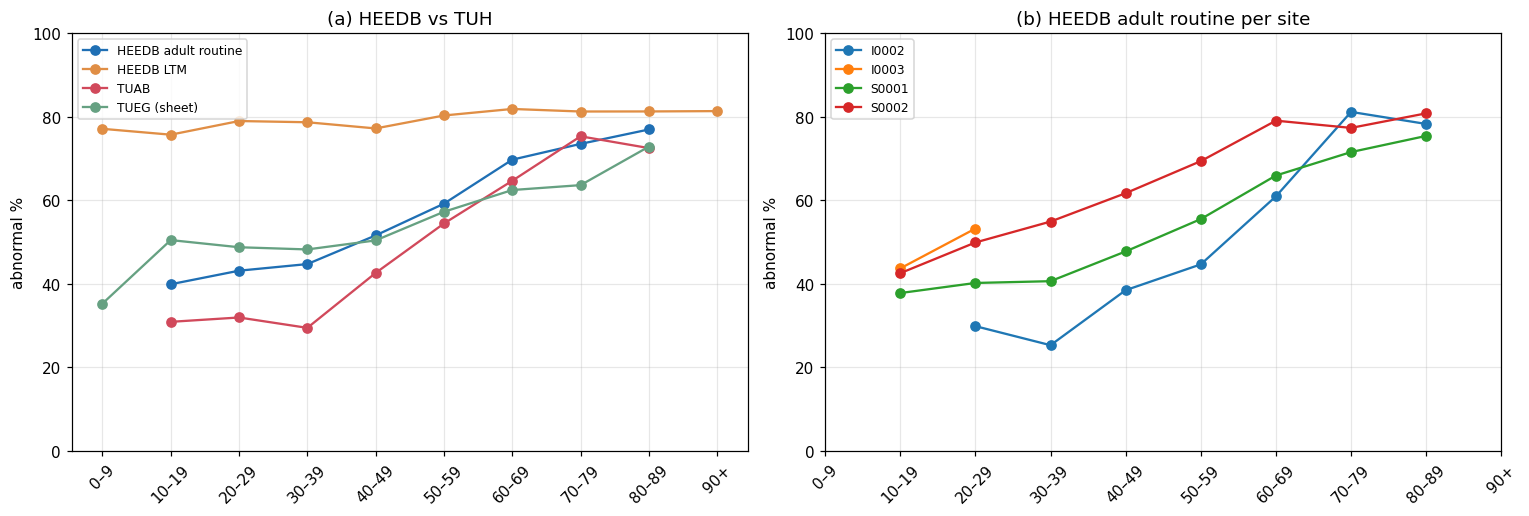

In [13]:
t_ab = ha.abnormal_rate_by_decade({"HEEDB adult routine": ar, "HEEDB LTM": main[main["service"].eq("LTM")],
                                   "TUAB": tuab, "TUEG (sheet)": tueg})
t_site = ha.abnormal_rate_by_decade({s: g for s, g in ar.groupby("site")})
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
x = np.arange(len(t_ab))
for col, c in zip(t_ab.columns, [C_H, "#e08e45", C_A, C_E]):
    axes[0].plot(x, t_ab[col], "o-", color=c, label=col)
for col in t_site.columns:
    axes[1].plot(x, t_site[col], "o-", label=col)
for ax in axes:
    ax.set_xticks(x, t_ab.index, rotation=45); ax.set_ylabel("abnormal %"); ax.set_ylim(0, 100); ax.legend(fontsize=8)
axes[0].set_title("HEEDB vs TUH"); axes[1].set_title("HEEDB adult routine per site")
finish(fig, axes)

### Table 4.2. Report findings in adult routine sessions

One row per finding, sorted by report mentions. `report`, `annotation`, `verified` = sessions
whose provenance string contains that source (a session can count in several); `report %` =
$p(x)$ of Eq. (4.2) over reported adult routine sessions; `mean age` (years) and `abnormal %`
of the sessions with the finding (report/verified). `group` = candidate target group
(`heedb_index.FINDING_GROUPS`).

In [14]:
t42 = ha.finding_table(ar).set_index("finding")
numbered_table(ha.suppress_small(t42, ["report", "annotation", "verified"]), "4.2", "Report findings in adult routine sessions", precision=1)

,group,report,annotation,verified,report %,mean age,abnormal %
finding,,,,,,,
n1,sleep,30669,15865,0,83.9,53.3,55.5
pdr,other,25994,10578,1360,71.7,52.9,52.5
gen_slowing,generalized_slowing,24999,10672,2036,69.3,56.8,74.5
n2,sleep,22405,8820,0,61.3,52.1,54.8
awake,other,20885,19781,0,57.2,52.4,48.2
vertex_wave,sleep,13692,8641,753,37.6,48.9,47.1
spindles,sleep,13218,8532,716,36.3,48.8,47.0
spikes,epileptiform,10210,14098,0,27.9,53.4,80.2
k_complexes,sleep,8462,3688,0,23.2,48.7,43.5


### Table 4.3. Finding groups as candidate targets

Per group of `heedb_index.FINDING_GROUPS` over reported adult routine sessions: `n` positive
sessions, prevalence (Eq. (4.2) on the group flag), `patients`, mean age and abnormal % of the
positives; `normal-report positives` = positives whose report is normal (expected for sleep and
normal variants, a warning sign for pathology groups).

In [15]:
lab = ar[ar["in_sheet"]]
rows = {}
for g in hx.FINDING_GROUPS:
    pos = lab[lab[f"fg_{g}"].fillna(False).astype(bool)]
    rows[g] = {"n": len(pos), "prevalence %": 100 * len(pos) / len(lab), "patients": pos["subject"].nunique(),
               "mean age": pos["age"].mean(), "abnormal %": 100 * pos["label"].eq("abnormal").mean(),
               "normal-report positives": int(pos["label"].eq("normal").sum())}
t43 = pd.DataFrame(rows).T.astype({"n": int, "patients": int, "normal-report positives": int})
numbered_table(ha.suppress_small(t43, ["n", "patients", "normal-report positives"]), "4.3", "Finding groups as candidate targets", precision=1)

,n,prevalence %,patients,mean age,abnormal %,normal-report positives
epileptiform,10534,28.8,8843,53.4,79.4,2167
seizure,5486,15.0,4900,54.2,66.4,1844
generalized_slowing,25558,70.0,21196,56.9,74.6,6483
focal_slowing,5606,15.3,4929,57.8,90.0,561
periodic_discharges,1684,4.6,1474,65.2,95.9,69
burst_suppression_low_voltage,892,2.4,819,59.5,89.0,98
normal_variants,3697,10.1,3462,49.8,53.7,1710
sleep,31869,87.2,27108,53.5,56.6,13816


### Figure 4.2. Pathology finding groups by age

Prevalence (Eq. (4.2)) of the pathology groups per age decade among reported adult routine
sessions. (a) Epileptiform, seizure, periodic discharges. (b) Generalized and focal slowing,
burst suppression / low voltage.

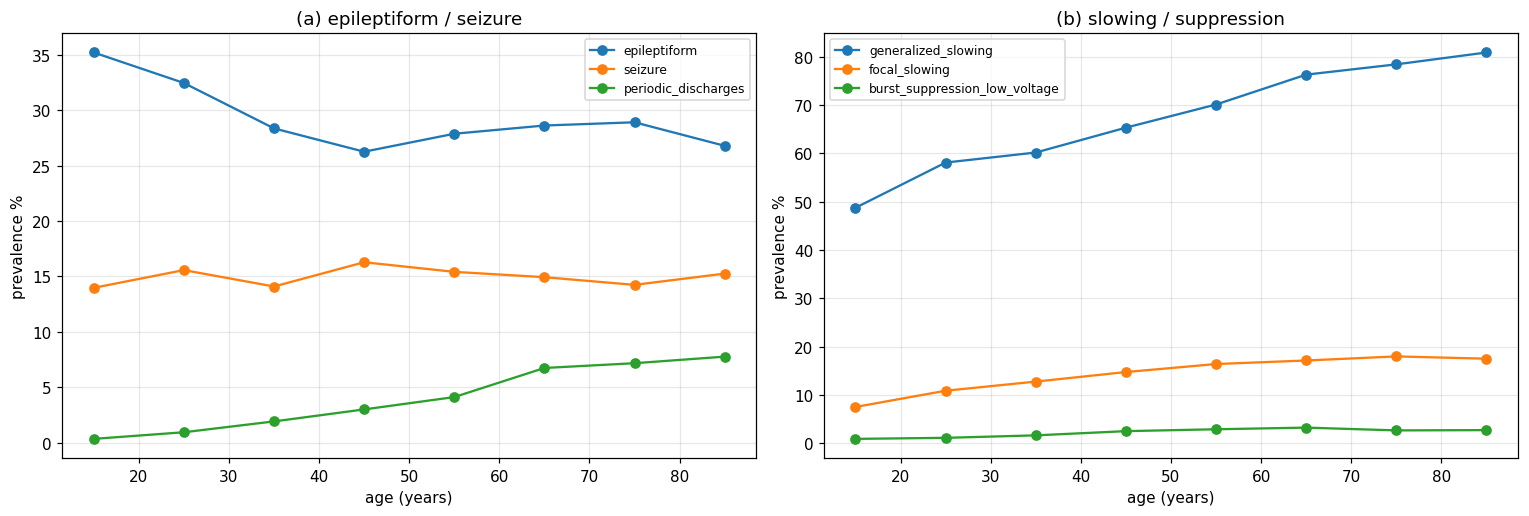

In [16]:
dec = pd.Series(hx.decade(lab["age"]), index=lab.index)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, gs in zip(axes, [["epileptiform", "seizure", "periodic_discharges"],
                         ["generalized_slowing", "focal_slowing", "burst_suppression_low_voltage"]]):
    for g in gs:
        r = 100 * lab[f"fg_{g}"].astype(float).groupby(dec).mean()
        ax.plot(r.index + 5, r.values, "o-", label=g)
    ax.set_xlabel("age (years)"); ax.set_ylabel("prevalence %"); ax.legend(fontsize=8)
axes[0].set_title("epileptiform / seizure"); axes[1].set_title("slowing / suppression")
finish(fig, axes)

## 5. Health records, aligned with the TUH clinical sheet

For TUEG, NEDC distributes one clinical row per session (15 Y/N diagnoses, a medication list,
the abnormal finding, FIRDA/OIRDA/TIRDA/GPD/LPD), cleaned by `dataset_maker/tuh_clinical.py`.
HEEDB gives **per-patient** ICD-10 codes and ATC drug groups instead. To compare the corpora —
and to reuse `tuh_clinical.normative_mask` / `report` unchanged — the index rebuilds every
sheet column from HEEDB sources (`heedb_index.tuh_aligned_flags`). Table 5.1 is the
crosswalk. Two rules carry over from TUH: a patient **without** any ICD (or medication) record
gets **unknown** (NA), not "healthy"; and `any_neuro_dx` / `sedated` are True if any member flag
is True. For a flag $c$ and the recordings $K_c$ where it is known, Table 5.2 reports

$$
\text{prev}(c) = 100 \cdot \frac{\lvert\{ i \in K_c : c_i \}\rvert}{\lvert K_c \rvert}\;\%,
\tag{5.1}
$$

$$
\Delta a(c) = \overline{a}_{\{i \in K_c :\, c_i\}} - \overline{a}_{\{i \in K_c :\, \neg c_i\}}\quad\text{(years)},
\tag{5.2}
$$

$$
\text{abn}(c) = 100 \cdot \frac{\lvert\{ i \in K_c : c_i,\ y_i = 1 \}\rvert}{\lvert\{ i \in K_c : c_i,\ y_i \text{ known} \}\rvert}\;\%
\tag{5.3}
$$

(`labram/eval/heedb_analysis.py::condition_table`; values with fewer than 20 positives are left
empty).

### Table 5.1. Crosswalk: TUH clinical columns rebuilt from HEEDB

One row per column of the cleaned NEDC sheet: kind, HEEDB source (ICD-10 / ATC prefixes, report
finding) and whether the match is exact, approximate or missing.

In [17]:
t51 = ha.crosswalk_table().set_index("TUH column")
numbered_table(t51, "5.1", "Crosswalk: TUH clinical columns rebuilt from HEEDB")

,kind,HEEDB source,match
TUH column,,,
dx_electrographic_seizure,diagnosis,report finding `seizure` (report/verified),exact
dx_clinical_seizure,diagnosis,"ICD-10 R56, G40, G41","approx. (per patient, undated)"
dx_stroke,diagnosis,"ICD-10 I60, I61, I62, I63, I64, I69","approx. (per patient, undated)"
dx_epilepsy,diagnosis,"ICD-10 G40, G41","approx. (per patient, undated)"
dx_parkinsons,diagnosis,"ICD-10 G20, G21","approx. (per patient, undated)"
dx_alzheimers,diagnosis,ICD-10 G30,"approx. (per patient, undated)"
dx_tbi,diagnosis,ICD-10 S06,"approx. (per patient, undated)"
dx_schizophrenia,diagnosis,"ICD-10 F20, F25","approx. (per patient, undated)"
dx_dementia,diagnosis,"ICD-10 F01, F02, F03, G30, G31.0, G31.1, G31.83","approx. (per patient, undated)"


### Table 5.2. Clinical flags: HEEDB adult routine vs TUEG

Per TUH clinical column (rows) and corpus (column groups): `known` recordings, `n` positives,
prevalence (Eq. (5.1)), mean age, age vs rest (Eq. (5.2)) and abnormal % (Eq. (5.3)).
HEEDB = adult routine sessions; TUEG = adult (18–89) recordings in the NEDC sheet.

In [18]:
flags = list(tuh_clinical.NEURO) + ["dx_depression", "dx_anxiety", "dx_bipolar", "dx_schizophrenia",
                                    "dx_substance", "dx_adhd", "f_gpd", "f_lpd", "f_firda", "f_tirda",
                                    "f_oirda"] + list(tuh_clinical.DRUG_CLASSES) + ["any_neuro_dx", "sedated"]
tueg_adult = tueg[tueg["age"].between(*hx.ADULT_AGE) & tueg["in_sheet"]]
cols = ["known", "n", "prevalence %", "mean age", "age vs rest", "abnormal %"]
t52 = pd.concat({"HEEDB adult routine": ha.condition_table(ar, flags)[cols],
                 "TUEG adults": ha.condition_table(tueg_adult, flags)[cols]}, axis=1)
numbered_table(ha.suppress_small(t52, [("HEEDB adult routine", "n"), ("TUEG adults", "n")]), "5.2", "Clinical flags: HEEDB adult routine vs TUEG", precision=1)

### Table 5.3. HEEDB ICD-10 categories (patient level)

The 18 neurology categories of `HEEDB_ICD10_for_Neurology.csv` (HEEDB only; TUH has no ICD codes),
over adult routine sessions of patients with at least one ICD record: positives, prevalence
(Eq. (5.1)), mean age, age vs rest (Eq. (5.2)), abnormal % (Eq. (5.3)).

In [19]:
icd_cols = [c for c in idx.columns if c.startswith("icd_") and c not in ("icd_codes", "icd_count")]
with_icd = ar[ar["icd_count"].fillna(0).gt(0) & ar["icd_codes"].notna()]
t53 = ha.condition_table(with_icd, icd_cols)[["known", "n", "prevalence %", "mean age", "age vs rest", "abnormal %"]]
t53.index = [c[4:] for c in t53.index]
numbered_table(ha.suppress_small(t53.sort_values("n", ascending=False), ["n"]), "5.3", "HEEDB ICD-10 categories (patient level)", precision=1)

,known,n,prevalence %,mean age,age vs rest,abnormal %
miscellaneous,30925,26146,84.5,55.7,17.0,61.8
seizure_disorders,30925,15502,50.1,49.9,-6.5,66.6
headache_disorders,30925,12291,39.7,54.5,2.3,61.3
cerebral_degeneration,30925,10220,33.0,64.6,17.2,74.7
sleep_disorders,30925,9368,30.3,57.8,6.7,60.8
cerebral_lobe_dysfunction,30925,7403,23.9,62.4,12.2,68.2
cerebrovascular_diseases,30925,6986,22.6,65.1,15.5,71.4
movement_and_cerebellar_disorders,30925,6659,21.5,58.4,6.7,65.1
other_neurological_disorders,30925,4283,13.8,59.1,6.9,76.8
behavioral_cognitive_syndromes,30925,3632,11.7,48.7,-5.0,60.0


### Figure 5.1. Age and abnormal rate per condition, HEEDB vs TUEG

(a) Mean age of recordings with each diagnosis (Table 5.2), HEEDB adult routine vs TUEG adults.
(b) Abnormal rate (Eq. (5.3)) for the same diagnoses. Only flags with ≥ 20 positives in both.

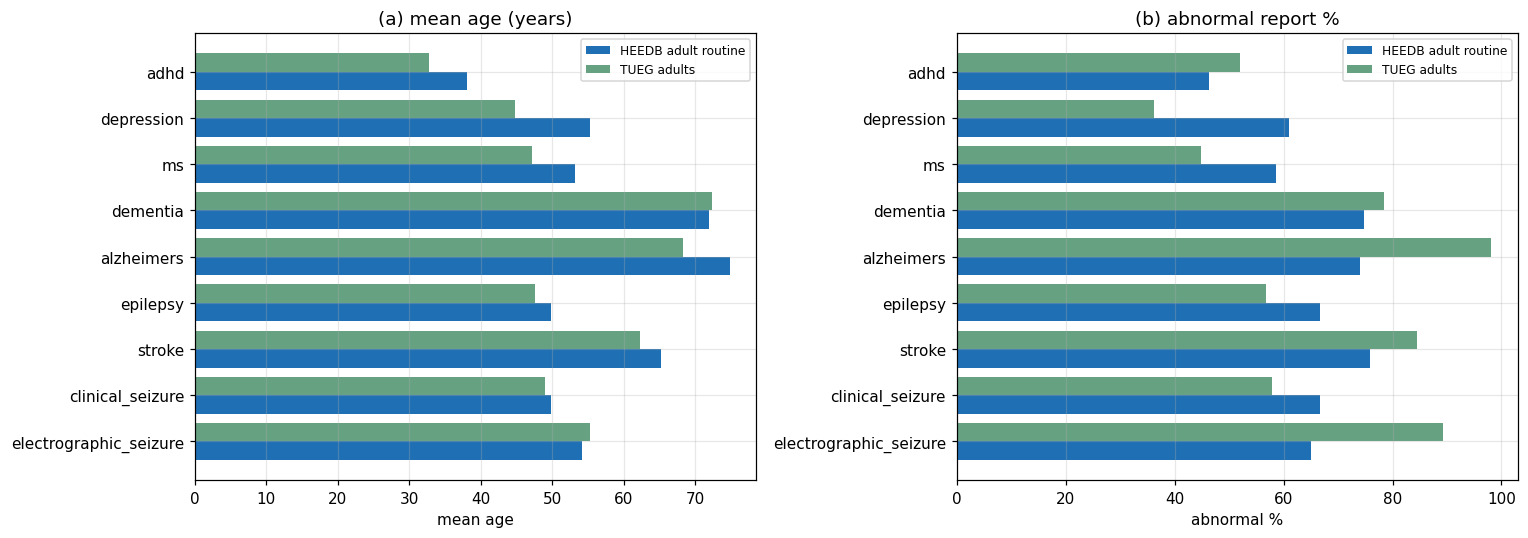

In [20]:
dx = [c for c in flags if c.startswith("dx_")]
both = t52.loc[dx].dropna(subset=[("HEEDB adult routine", "mean age"), ("TUEG adults", "mean age")])
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
y = np.arange(len(both))
for ax, col in zip(axes, ["mean age", "abnormal %"]):
    ax.barh(y - 0.2, both[("HEEDB adult routine", col)], 0.4, color=C_H, label="HEEDB adult routine")
    ax.barh(y + 0.2, both[("TUEG adults", col)], 0.4, color=C_E, label="TUEG adults")
    ax.set_yticks(y, [c[3:] for c in both.index]); ax.set_xlabel(col); ax.legend(fontsize=8)
axes[0].set_title("mean age (years)"); axes[1].set_title("abnormal report %")
finish(fig, axes)

## 6. Cohorts for brain age

Our TUH brain-age cohorts start from `tuh_clinical.normative_mask`: in the sheet, report-normal,
no neurological diagnosis, no sedating drug, age 18–89. Applied unchanged to HEEDB (the flags of
Table 5.1), the **medication** term behaves differently: HEEDB medications are every drug group
ever prescribed to the patient, not the drugs at the time of the EEG, so most hospital patients
are "sedated" (Table 5.2). And `any_neuro_dx` is only known for patients with an ICD record, so
requiring it to be False drops every patient without a health record. Table 6.1 therefore counts
four nested rules; "no *known* neuro dx" (report-normal, no neurological ICD code or seizure
finding, patients without a record allowed) is the HEEDB analogue of the TUH healthy cohort.

### Table 6.1. Normative candidates per age decade

Adult routine sessions per decade: report-normal; + no known neurological diagnosis
(`any_neuro_dx` not True); + no neurological diagnosis with an ICD record (`any_neuro_dx` False);
+ not sedated (the full TUH rule). TUEG column = the full TUH rule on TUEG adults, for scale.
Counts.

In [21]:
t61 = ha.normative_counts(ar)
tn = tuh_clinical.normative_mask(tueg)
t61["TUEG (TUH rule)"] = list(pd.Series(hx.decade(tueg.loc[tn, "age"])).value_counts()
                              .reindex(range(10, 90, 10), fill_value=0)) + [int(tn.sum())]
numbered_table(ha.suppress_small(t61), "6.1", "Normative candidates per age decade", precision=0)

,"report-normal, 18–89",+ no known neuro dx,+ no neuro dx (ICD record),+ not sedated (TUH rule),TUEG (TUH rule)
10–19,719,432,256,69,199
20–29,2806,1465,888,162,2170
30–39,2112,1165,702,89,2006
40–49,1845,998,574,51,2492
50–59,2316,1240,742,56,2914
60–69,2200,1133,659,36,2004
70–79,1695,835,510,33,1029
80–89,794,364,183,15,342
total,14487,7632,4514,511,13156


## 7. The EEG signal: headers

The header of every adult routine EDF was read by an S3 range request
(`heedb_index.fetch_header` / `header_row`; 256 bytes + 256 per signal) — the same fields the TUH
scan records (`tuh_metadata.recording_row`) plus units, prefilter and amplitude resolution. The
digital resolution of a channel with physical range $[P_-, P_+]$ (µV) stored in the digital range
$[D_-, D_+]$ is

$$
\text{LSB} = \frac{P_+ - P_-}{D_+ - D_-}\quad\text{µV per digital unit}.
\tag{7.1}
$$

HEEDB channel labels are bare BIDS names (`Fp1`, `T7`); `tuh_metadata.bids_canonical_channel`
maps them onto the 23 TUH channels (the 10-10 names T7/T8/P7/P8 become T3/T4/T5/T6).

### Table 7.1. Header facts of adult routine EDFs vs TUH

Share (%) of recordings per value: native sampling rate (Hz), EDF type, physical unit, number of
the 23 TUH channels present, and the median LSB (Eq. (7.1)). HEEDB = adult routine EDFs with a
scanned header; TUH = all TUAB + TUEG recordings (`tuh_index`; units and LSB not in that index).

In [22]:
def shares(s, top=6):
    v = s.value_counts(normalize=True).head(top) * 100
    return "; ".join(f"{k}: {p:.1f}%" for k, p in v.items())
t71 = pd.DataFrame({
    "HEEDB adult routine": {
        "recordings": f"{len(hdr):,}", "sampling rate (Hz)": shares(hdr["sfreq"].dropna().round(0).astype(int)),
        "EDF type": shares(hdr["edf_type"]), "unit": shares(hdr["units"]),
        "TUH channels present (of 23)": shares(hdr["n_tuh_channels"].astype(int)),
        "no 10-20 channel found": f"{int(hdr['sfreq'].isna().sum())} recordings",
        "signals per file": f"median {hdr['n_signals'].median():.0f} (p5 {hdr['n_signals'].quantile(.05):.0f}, p95 {hdr['n_signals'].quantile(.95):.0f})",
        "median LSB (µV, Eq. 7.1)": f"{hdr['lsb_uv'].median():.3f}",
        "prefilter field": shares(hdr["prefilter"].replace("", "(empty)")),
        "header vs metadata length": f"median |Δ| {(hdr['header_duration_sec'] - hdr['duration_sec']).abs().median():.0f} s"},
    "TUH (TUAB + TUEG)": {
        "recordings": f"{len(tuh):,}", "sampling rate (Hz)": shares(tuh["sfreq"].dropna().round(0).astype(int)),
        "EDF type": "EDF", "unit": "uV (TUH QC sample)",
        "TUH channels present (of 23)": shares(tuh["missing_channels"].map(lambda m: 23 - len(m))),
        "signals per file": f"median {tuh['n_signals'].median():.0f} (p5 {tuh['n_signals'].quantile(.05):.0f}, p95 {tuh['n_signals'].quantile(.95):.0f})",
        "no 10-20 channel found": "–",
        "median LSB (µV, Eq. 7.1)": "–", "prefilter field": "HP/LP/N fields, mostly placeholders",
        "header vs metadata length": "–"},
})
numbered_table(t71, "7.1", "Header facts of adult routine EDFs vs TUH")

,HEEDB adult routine,TUH (TUAB + TUEG)
recordings,"72,118","71,348"
sampling rate (Hz),200: 68.3%; 256: 20.8%; 512: 10.8%; 1024: 0.1%; 4096: 0.0%; 2048: 0.0%,256: 51.3%; 250: 37.4%; 1000: 4.4%; 400: 4.4%; 512: 2.4%
EDF type,EDF+C: 100.0%,EDF
unit,uV: 100.0%,uV (TUH QC sample)
TUH channels present (of 23),19: 70.0%; 21: 29.9%; 2: 0.1%; 13: 0.0%,23: 78.1%; 21: 17.4%; 19: 4.4%; 17: 0.1%; 22: 0.0%; 0: 0.0%
no 10-20 channel found,0 recordings,–
signals per file,"median 31 (p5 23, p95 51)","median 33 (p5 28, p95 41)"
"median LSB (µV, Eq. 7.1)",0.266,–
prefilter field,(empty): 66.0%; None: 34.0%,"HP/LP/N fields, mostly placeholders"
header vs metadata length,median |Δ| 1 s,–


### Figure 7.1. Channel coverage

(a) Share (%) of recordings in which each of the 23 TUH channels is present (bare BIDS label
mapped by `bids_canonical_channel`), HEEDB adult routine vs TUH. (b) Auxiliary channel types in
HEEDB adult routine EDFs (`heedb_index.AUX_PATTERNS`, % of recordings).

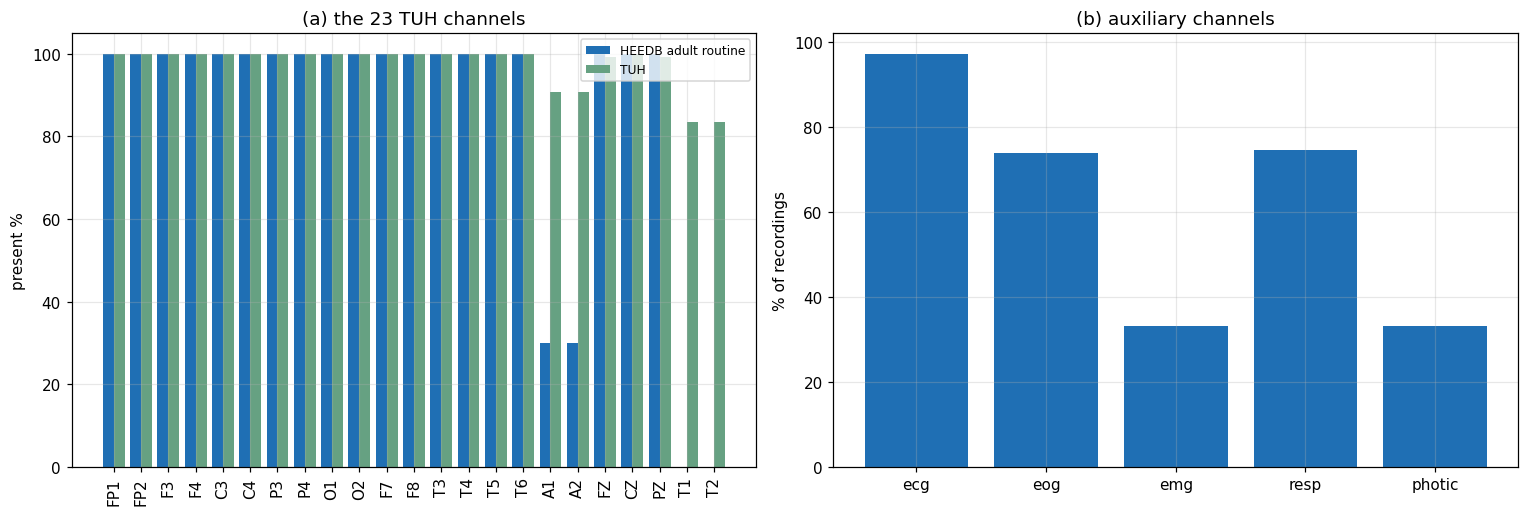

In [23]:
cp_h = ha.channel_presence(hdr)
cp_t = ha.channel_presence(tuh)
aux = hdr[[c for c in hx.AUX_PATTERNS]].mean() * 100
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
x = np.arange(len(TUH_CHANNELS))
axes[0].bar(x - 0.2, cp_h["present %"], 0.4, color=C_H, label="HEEDB adult routine")
axes[0].bar(x + 0.2, cp_t["present %"], 0.4, color=C_E, label="TUH")
axes[0].set_xticks(x, TUH_CHANNELS, rotation=90); axes[0].set_ylabel("present %"); axes[0].legend(fontsize=8)
axes[0].set_title("the 23 TUH channels")
axes[1].bar(range(len(aux)), aux.values, color=C_H)
axes[1].set_xticks(range(len(aux)), [a[4:] for a in aux.index]); axes[1].set_ylabel("% of recordings")
axes[1].set_title("auxiliary channels")
finish(fig, axes)

### Table 7.2. Sampling rate per site

Adult routine EDFs with a scanned header: share (%) of each native sampling rate (Hz) per site, and
the number of headers. Cells with fewer than 10 recordings show `<10 rec.` (small-cell suppression).

In [24]:
h72 = hdr[hdr["sfreq"].notna()]
c72 = pd.crosstab(h72["site"], h72["sfreq"].round(0).astype(int))
t72 = (100 * c72.div(c72.sum(axis=1), axis=0)).round(1).astype(object).where(~c72.isin(range(1, 10)), "<10 rec.")
t72["headers"] = hdr.groupby("site").size()
numbered_table(t72, "7.2", "Sampling rate per site", precision=1)

sfreq,200,256,500,512,1024,2048,4096,16384,headers
site,,,,,,,,,
I0002,11.1,80.2,0.0,7.8,0.5,0.1,0.2,<10 rec.,11634
I0003,7.2,66.4,0.0,26.2,<10 rec.,<10 rec.,0.0,0.0,1605
S0001,73.9,7.0,<10 rec.,19.1,0.0,<10 rec.,0.0,0.0,33621
S0002,91.1,8.9,0.0,0.0,<10 rec.,0.0,0.0,0.0,25258


## 8. The EEG signal: content and line noise

The header says nothing about the signal itself. A **stratified sample** of adult routine EDFs —
up to 30 per site × report label (normal, abnormal, unlabelled), one per patient
(`heedb_analysis.stratified_sample`) — was measured exactly like the TUH QC sample of
`notebooks/tuh_preprocessing_analysis.ipynb` (`preprocessing_qc.analyze_recording`, 187 TUAB/TUEG
recordings). One difference: many HEEDB files contain long **flat** stretches (amplifier on,
no signal) and non-physiological stretches (electrodes not yet attached), so each recording is
first probed at 12 evenly spaced 10 s excerpts (`heedb_analysis.signal_profile`). With
$\sigma_{c,j}$ the standard deviation (µV) of channel $c$ in probe $j$ and $C$ the TUH channels present,

$$
\begin{aligned}
\text{flat}_j &= \Big[\tfrac{1}{\lvert C\rvert}\textstyle\sum_{c \in C} [\sigma_{c,j} < 0.5\,\text{µV}] \ge 0.5\Big],\\
\text{flat time} &= \tfrac{1}{12}\textstyle\sum_{j=1}^{12} \text{flat}_j ,
\end{aligned}
\tag{8.1}
$$

$$
\begin{aligned}
\text{noisy}_j &= \neg\text{flat}_j \wedge \big[\operatorname{median}_{c} \sigma_{c,j} \notin [2, 150]\,\text{µV}\big],\\
\text{noisy time} &= \tfrac{1}{12}\textstyle\sum_{j=1}^{12} \text{noisy}_j .
\end{aligned}
\tag{8.2}
$$

The spectral measures use 120 s of non-flat data records starting at the middle physiological
probe. The line-noise prominence of a frequency $f_0$ in the channel-median Welch PSD $P$
(4 s Hann, 50 % overlap) is (`preprocessing_qc.line_prominence_db`)

$$
\text{LNP}(f_0) = 10\log_{10}\frac{\operatorname{mean} P\big([f_0-0.5,\ f_0+0.5]\big)}
{\operatorname{median} P\big([f_0-5,\ f_0-2] \cup [f_0+2,\ f_0+5]\big)}\quad\text{dB},
\tag{8.3}
$$

~0 dB = no line. 76 Hz is where the 180 Hz harmonic folds to when sampled at 256 Hz
($256 - 180 = 76$). Amplitude measures (`preprocessing_qc.amplitude_stats`): median and 99th
percentile of $\lvert x\rvert$ (µV), `clip_frac` = share of samples at ≥ 99.5 % of the physical
maximum, `flat_channel_frac` = share of channels flat in some 10 s window, `dc_offset_uv` =
median over channels of $\lvert\overline{x}_c\rvert$ (µV).

In [25]:
sample = ha.stratified_sample(ar_edf, per_cell=30)
qt, qs = ha.analyze_sample(sample["key"], cache=f"{ROOT}/cache/signal_qc_sample_v1.pkl", workers=8)
qh = qt.merge(sample[["key", "site", "label", "age", "sfreq"]], on="key", how="left")
ok = qh[qh["error"].isna()] if "error" in qh else qh
tuh_qc, tuh_spec = pickle.load(open(ha.TUH_QC, "rb"))
tuh_qc = tuh_qc.merge(pd.read_parquet(Path(ha.TUH_QC).parent / "sample.parquet")[["stem", "group"]], on="stem")
print(f"HEEDB sample: {len(qh)} EDFs, {len(ok)} analysed, "
      f"{len(qh) - len(ok)} without a physiological probe | TUH QC sample: {len(tuh_qc)}")

HEEDB sample: 360 EDFs, 358 analysed, 2 without a physiological probe | TUH QC sample: 187


### Table 8.1. Signal integrity, HEEDB sample vs TUH QC sample

Median (and share of recordings where relevant) of: flat time (Eq. (8.1)), noisy time
(Eq. (8.2)), recordings flat ≥ 25 % of the time, time of the first non-flat probe (s), median
and 99th-percentile $\lvert x\rvert$ (µV), clip fraction, flat-channel fraction and DC offset (µV)
of the analysed 120 s. TUH has no flat/noisy probes (its QC used 60–180 s directly).

In [26]:
def integrity(d, probes=True):
    out = {"recordings": len(d)}
    if probes:
        out |= {"median flat time %": 100 * d["flat_time_frac"].median(),
                "mean flat time %": 100 * d["flat_time_frac"].mean(),
                "recordings flat ≥ 25 % (%)": 100 * (d["flat_time_frac"] >= 0.25).mean(),
                "mean noisy time %": 100 * d["noisy_time_frac"].mean(),
                "median first signal (s)": d["first_signal_sec"].median()}
    out |= {"median |x| (µV)": d["median_abs_uv"].median(), "p99 |x| (µV)": d["p99_abs_uv"].median(),
            "clip frac (%)": 100 * d["clip_frac"].mean(), "flat channel frac (%)": 100 * d["flat_channel_frac"].mean(),
            "DC offset (µV)": d["dc_offset_uv"].median()}
    return out
t81 = pd.DataFrame({"HEEDB sample (all)": integrity(qh),
                    **{f"HEEDB {s}": integrity(g) for s, g in qh.groupby("site")},
                    "TUAB QC": integrity(tuh_qc[tuh_qc["group"] == "TUAB"], probes=False),
                    "TUEG QC": integrity(tuh_qc[tuh_qc["group"] == "TUEG"], probes=False)})
numbered_table(t81, "8.1", "Signal integrity, HEEDB sample vs TUH QC sample", precision=1)

,HEEDB sample (all),HEEDB I0002,HEEDB I0003,HEEDB S0001,HEEDB S0002,TUAB QC,TUEG QC
recordings,360.0,90.0,90.0,90.0,90.0,80.0,107.0
median flat time %,16.7,0.0,0.0,33.3,41.7,–,–
mean flat time %,21.1,2.5,10.6,27.5,43.6,–,–
recordings flat ≥ 25 % (%),46.7,2.2,21.1,70.0,93.3,–,–
mean noisy time %,10.1,7.3,5.8,15.2,11.9,–,–
median first signal (s),0.0,0.0,0.0,0.0,0.0,–,–
median |x| (µV),22.2,20.6,23.1,23.2,23.0,8.7,15.3
p99 |x| (µV),114.7,101.2,108.2,138.7,129.5,80.0,124.5
clip frac (%),0.7,0.0,0.0,0.2,2.8,0.0,0.1
flat channel frac (%),0.0,0.0,0.0,0.0,0.1,0.0,0.0


### Figure 8.1. Flat signal inside HEEDB recordings

(a) Flat time per recording (Eq. (8.1)), density over the sample, per site. (b) State of each of
the 12 probes by its position in the recording (probe 1 = start, 12 = last 10 s): share (%) of
recordings in which the probe is flat (Eq. (8.1)), noisy (Eq. (8.2)) or physiological signal.

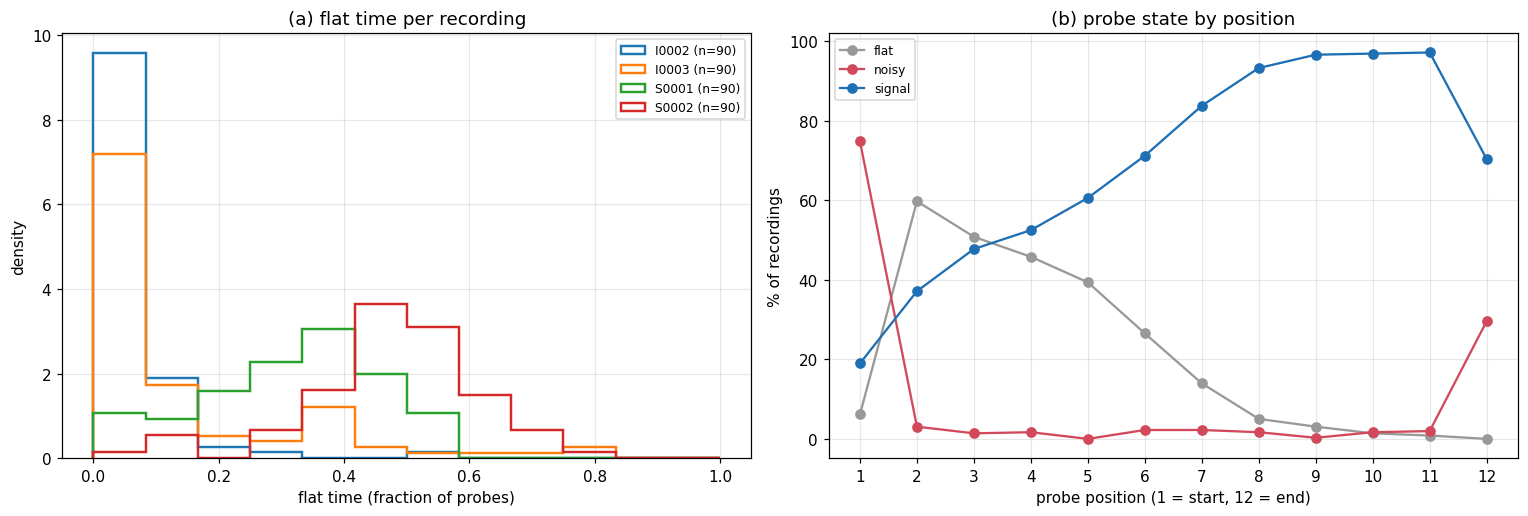

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
b = np.linspace(0, 1, 13)
for s, g in qh.groupby("site"):
    axes[0].hist(g["flat_time_frac"].dropna(), bins=b, histtype="step", lw=1.6, density=True, label=f"{s} (n={len(g)})")
axes[0].set_xlabel("flat time (fraction of probes)"); axes[0].set_ylabel("density"); axes[0].legend(fontsize=8)
axes[0].set_title("flat time per recording")
pat = np.array([list(p) for p in qh["probe_pattern"].dropna()])
pos = np.arange(1, pat.shape[1] + 1)
for k, name, c in [("F", "flat", "#999999"), ("N", "noisy", C_A), ("S", "signal", C_H)]:
    axes[1].plot(pos, 100 * (pat == k).mean(axis=0), "o-", color=c, label=name)
axes[1].set_xticks(pos); axes[1].set_xlabel("probe position (1 = start, 12 = end)")
axes[1].set_ylabel("% of recordings"); axes[1].legend(fontsize=8); axes[1].set_title("probe state by position")
finish(fig, axes)

### Table 8.2. Mains and harmonic lines in the raw signal

Per corpus: median LNP (Eq. (8.3), dB) of the raw channel-median PSD at 50, 60, 76 (180 Hz alias at
256 Hz) and 120 Hz, and the share (%) of recordings with LNP > 3 dB (a visible line).

In [28]:
def lines(d):
    out = {}
    for f0 in (50, 60, 76, 120):
        v = d[f"raw_lnp_{f0}"]
        out[f"LNP {f0} Hz (dB)"] = v.median()
        out[f"{f0} Hz line > 3 dB (%)"] = 100 * (v > 3).mean()
    return out
t82 = pd.DataFrame({"HEEDB sample": lines(ok), "TUAB QC": lines(tuh_qc[tuh_qc["group"] == "TUAB"]),
                    "TUEG QC": lines(tuh_qc[tuh_qc["group"] == "TUEG"])}).T
numbered_table(t82, "8.2", "Mains and harmonic lines in the raw signal", precision=1)

,LNP 50 Hz (dB),50 Hz line > 3 dB (%),LNP 60 Hz (dB),60 Hz line > 3 dB (%),LNP 76 Hz (dB),76 Hz line > 3 dB (%),LNP 120 Hz (dB),120 Hz line > 3 dB (%)
HEEDB sample,-0.0,0.0,11.5,83.2,0.3,12.0,0.2,5.9
TUAB QC,0.1,0.0,1.9,37.5,0.1,0.0,-0.3,6.2
TUEG QC,-0.0,0.0,4.7,60.7,0.0,0.9,0.7,27.1


### Figure 8.2. Grand-average spectrum, raw

Median over recordings of the channel-median PSD (µV²/Hz, log scale) of the raw 120 s excerpts,
interpolated onto a common 0.25 Hz grid. (a) 0.5–100 Hz, HEEDB sample vs TUAB and TUEG QC
samples. (b) 40–100 Hz zoom with 50/60/76 Hz marked.

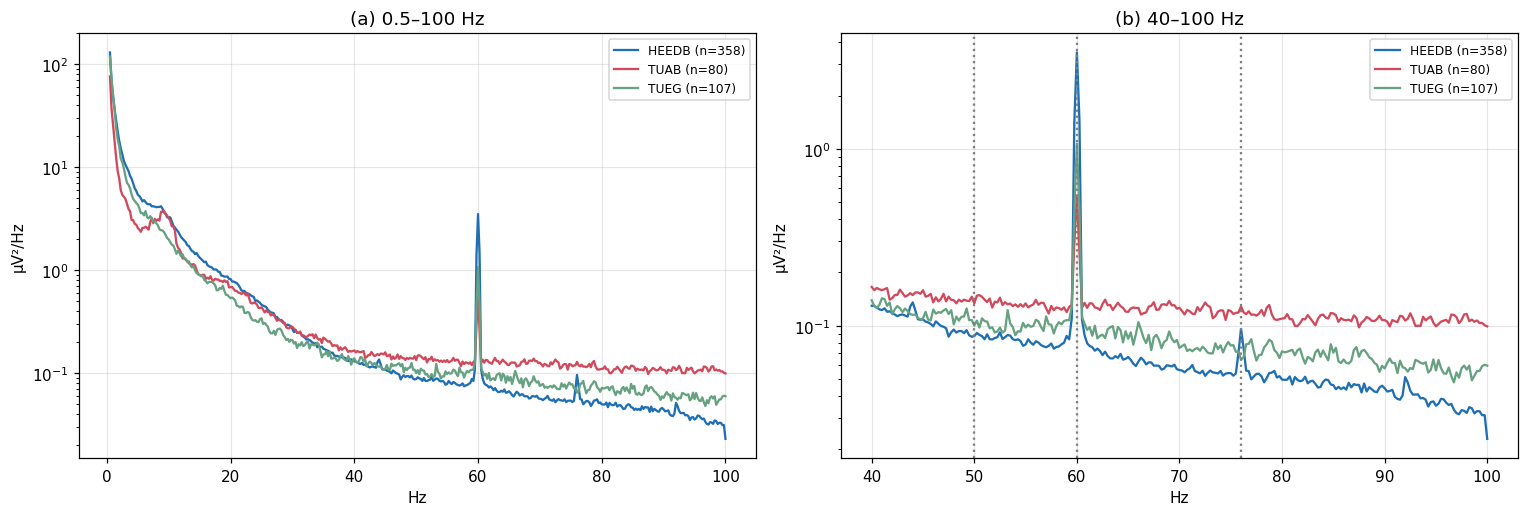

In [29]:
grid = np.arange(0.5, 100.01, 0.25)


def grand(spec, keys, name="raw_psd"):
    rows = []
    for k in keys:
        if k in spec and name in spec[k]:
            f, p = spec[k][name]
            if f[-1] >= grid[-1]:
                rows.append(np.interp(grid, f, np.log10(np.maximum(p, 1e-12))))
    return 10 ** np.median(rows, axis=0), len(rows)


g_h, n_h = grand(qs, ok["key"])
g_a, n_a = grand(tuh_spec, tuh_qc.loc[tuh_qc["group"] == "TUAB", "stem"])
g_e, n_e = grand(tuh_spec, tuh_qc.loc[tuh_qc["group"] == "TUEG", "stem"])
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, lo in zip(axes, (0.5, 40)):
    sel = grid >= lo
    for g, n, name, c in [(g_h, n_h, "HEEDB", C_H), (g_a, n_a, "TUAB", C_A), (g_e, n_e, "TUEG", C_E)]:
        ax.semilogy(grid[sel], g[sel], color=c, label=f"{name} (n={n})")
    ax.set_xlabel("Hz"); ax.set_ylabel("µV²/Hz"); ax.legend(fontsize=8)
for f0 in (50, 60, 76):
    axes[1].axvline(f0, c="gray", ls=":")
axes[0].set_title("0.5–100 Hz"); axes[1].set_title("40–100 Hz")
finish(fig, axes)

### Table 8.3. Line left at the model input, per preprocessing protocol

For each protocol of `preprocessing_qc` (band-pass 0.1–75 Hz, the named line removal, resample to
200 Hz): median LNP (Eq. (8.3), dB) after processing at 60 Hz and at 76 Hz, and the share (%) of
55–65 Hz power in the 0.5–75 Hz band (`band_fraction`), HEEDB sample vs TUEG QC sample. LaBraM =
the original 50 Hz notch; interpolation = `labram/data/line_removal.py::spectrum_interpolate`.

In [30]:
protos = [qc.LABRAM.name, qc.BANDPASS_ONLY.name, "60 Hz notch", "60 Hz spectrum interpolation",
          qc.INTERP_BOTH.name, "60 Hz notch, 45 Hz low-pass"]
rows = {}
for p in protos:
    for corpus, d in [("HEEDB", ok), ("TUEG", tuh_qc[tuh_qc["group"] == "TUEG"])]:
        if f"{p}|lnp_60" in d:
            rows[(p, corpus)] = {"LNP 60 Hz (dB)": d[f"{p}|lnp_60"].median(),
                                 "LNP 76 Hz (dB)": d[f"{p}|lnp_76"].median(),
                                 "55–65 Hz power share (%)": 100 * d[f"{p}|frac_55_65"].median()}
t83 = pd.DataFrame(rows).T
numbered_table(t83, "8.3", "Line left at the model input, per preprocessing protocol", precision=2)

### Figure 8.3. Spectrum at the model input, HEEDB

Median channel-median PSD of the HEEDB sample after each protocol (output at 200 Hz, µV²/Hz, log).
(a) 0.5–75 Hz. (b) 45–80 Hz zoom: the LaBraM recipe (50 Hz notch) leaves the 60 Hz line, a
notch cuts a hole, interpolation removes the line without one.

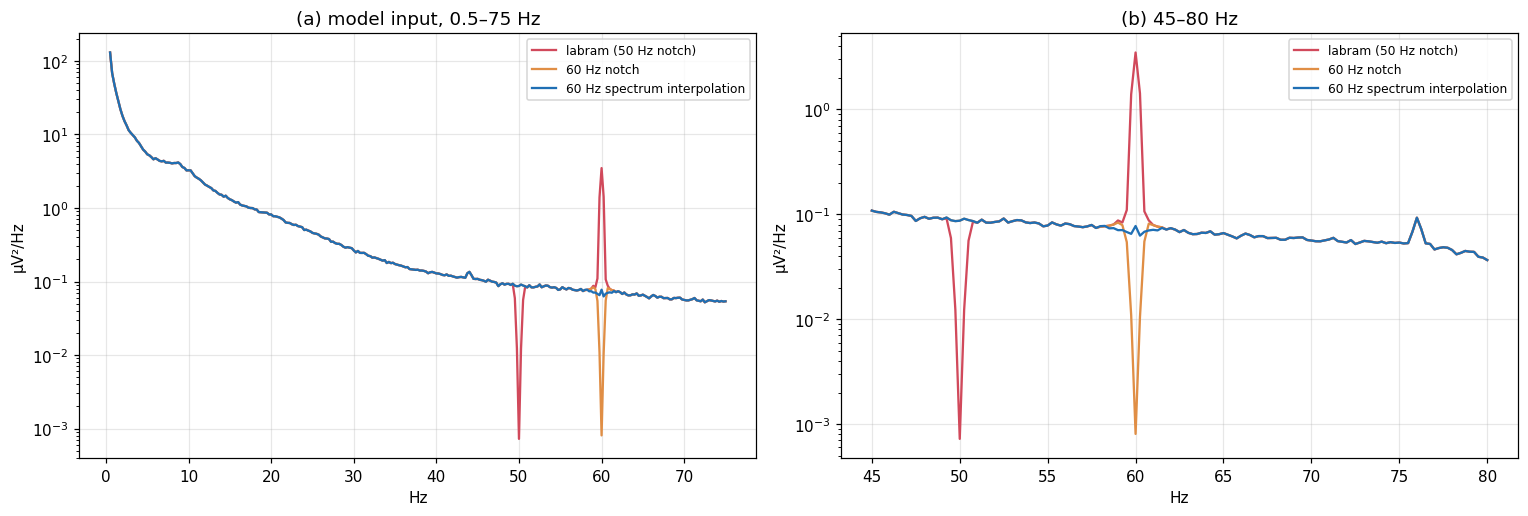

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
grid2 = np.arange(0.5, 80.01, 0.25)


def grand_on(spec, keys, name, grid):
    rows = [np.interp(grid, spec[k][name][0], np.log10(np.maximum(spec[k][name][1], 1e-12)))
            for k in keys if name in spec.get(k, {})]
    return 10 ** np.median(rows, axis=0)


for p, c in zip([qc.LABRAM.name, "60 Hz notch", "60 Hz spectrum interpolation"], [C_A, "#e08e45", C_H]):
    g = grand_on(qs, ok["key"], f"{p}|psd", grid2)
    for ax, lo, hi in [(axes[0], 0.5, 75), (axes[1], 45, 80)]:
        sel = (grid2 >= lo) & (grid2 <= hi)
        ax.semilogy(grid2[sel], g[sel], color=c, label=p)
for ax in axes:
    ax.set_xlabel("Hz"); ax.set_ylabel("µV²/Hz"); ax.legend(fontsize=8)
axes[0].set_title("model input, 0.5–75 Hz"); axes[1].set_title("45–80 Hz")
finish(fig, axes)

## 9. Recommended data preparation and filtering

The TUH recipe (`dataset_maker/make_TUH_npy.py`, analysed in
`notebooks/tuh_preprocessing_analysis.ipynb`) carries over to HEEDB with the changes Sections 7–8
call for. The output contract stays **identical** — per-recording `recordings/<stem>.npy`
`[T, 23]` at 200 Hz in µV, whole 10 s windows, `manifest.json` with a per-recording channel mask —
so `TUABAgeNpyLoader`, window QC, cohort building and training read HEEDB exactly like TUH.

### Table 9.1. TUH recipe vs recommended HEEDB recipe

One row per step: what the TUH pipeline does, what HEEDB needs, and the evidence (table/figure of
this notebook).

In [32]:
t91 = pd.DataFrame([
    ("selection", "TUAB/TUEG, age 1–89, ≥ 60 s",
     "routine service (Eq. 2.1), age 18–89, 10–240 min; drop files with < 19 of the 23 channels (43 have 2)",
     "Tables 2.1, 3.3, 7.1"),
    ("channels", "`EEG X-REF/LE` → 23 TUH channels, missing zero-filled + mask",
     "bare BIDS labels via `bids_canonical_channel` (T7/T8/P7/P8 → T3/T4/T5/T6) → same 23 + mask; "
     "A1/A2 absent in 70 % and T1/T2 in all files → train with missing-channel handling "
     "(`channel_drop`, as the TUH `anymiss` cohorts)", "Table 7.1, Figure 7.1(a)"),
    ("reference", "referential, CAR at train time (`labram_plus`)",
     "referential; same CAR at train time (also removes the larger DC offset)", "Tables 7.1, 8.1"),
    ("band-pass", "0.1–75 Hz zero-phase FIR (MNE)", "same", "Figure 8.2"),
    ("line removal", "spectrum interpolation at 50 + 60 Hz (`interp50-60`)",
     "spectrum interpolation at 60 Hz (the TUEG recipe works unchanged; 50 Hz is a no-op); "
     "the 76 Hz alias of 180 Hz lies above the 75 Hz band edge", "Tables 8.2–8.3, Figure 8.3"),
    ("resampling", "native 250–1000 Hz → 200 Hz (FFT)",
     "most files are already 200 Hz (no resampling); 256/512 Hz → 200 Hz", "Table 7.2"),
    ("units / dtype", "µV, float16 npy", "µV (all headers in uV), float16 npy", "Table 7.1"),
    ("flat / dead signal", "window QC `min_std` 0.5 µV (opt-in)",
     "required: detect flat records at conversion time and drop flat 10 s windows "
     "(S0001/S0002 files are flat for long stretches in their first half); record per-window "
     "stats in `window_stats.npz`", "Table 8.1, Figure 8.1"),
    ("artifact windows", "window QC `max_abs` 800 µV (opt-in)",
     "on by default; also drop the first/last probe-length of non-physiological signal", "Table 8.1, Figure 8.1(b)"),
    ("amplitude scale", "µV as recorded", "µV as recorded; check per-site scale after filtering "
     "(raw median |x| 22 µV vs 9–15 µV in TUH, partly DC); per-patch z-scoring (`labram_plus`) neutralises it",
     "Table 8.1"),
    ("labels", "age from EDF header; abnormal from TUAB folder / NEDC sheet",
     "age from metadata (`AgeAtVisit`); abnormal from the report; findings only after validation "
     "(negations are counted); ICD/ATC flags per patient (Table 5.1)", "Sections 4–5"),
], columns=["step", "TUH (current)", "HEEDB (recommended)", "evidence"]).set_index("step")
numbered_table(t91, "9.1", "TUH recipe vs recommended HEEDB recipe")

,TUH (current),HEEDB (recommended),evidence
step,,,
selection,"TUAB/TUEG, age 1–89, ≥ 60 s","routine service (Eq. 2.1), age 18–89, 10–240 min; drop files with < 19 of the 23 channels (43 have 2)","Tables 2.1, 3.3, 7.1"
channels,"`EEG X-REF/LE` → 23 TUH channels, missing zero-filled + mask","bare BIDS labels via `bids_canonical_channel` (T7/T8/P7/P8 → T3/T4/T5/T6) → same 23 + mask; A1/A2 absent in 70 % and T1/T2 in all files → train with missing-channel handling (`channel_drop`, as the TUH `anymiss` cohorts)","Table 7.1, Figure 7.1(a)"
reference,"referential, CAR at train time (`labram_plus`)",referential; same CAR at train time (also removes the larger DC offset),"Tables 7.1, 8.1"
band-pass,0.1–75 Hz zero-phase FIR (MNE),same,Figure 8.2
line removal,spectrum interpolation at 50 + 60 Hz (`interp50-60`),spectrum interpolation at 60 Hz (the TUEG recipe works unchanged; 50 Hz is a no-op); the 76 Hz alias of 180 Hz lies above the 75 Hz band edge,"Tables 8.2–8.3, Figure 8.3"
resampling,native 250–1000 Hz → 200 Hz (FFT),most files are already 200 Hz (no resampling); 256/512 Hz → 200 Hz,Table 7.2
units / dtype,"µV, float16 npy","µV (all headers in uV), float16 npy",Table 7.1
flat / dead signal,window QC `min_std` 0.5 µV (opt-in),required: detect flat records at conversion time and drop flat 10 s windows (S0001/S0002 files are flat for long stretches in their first half); record per-window stats in `window_stats.npz`,"Table 8.1, Figure 8.1"
artifact windows,window QC `max_abs` 800 µV (opt-in),on by default; also drop the first/last probe-length of non-physiological signal,"Table 8.1, Figure 8.1(b)"


## 10. Plan: onboarding HEEDB like TUH

Each TUH pipeline stage has a HEEDB counterpart (Table 10.1); most reuse the TUH code with a
pluggable corpus adapter. The data move is a **single pass over all adult routine sessions**
(Table 10.2), copied server-side from the BDSP access point into a private, KMS-encrypted
bucket in our account (same region, no egress), then converted to npy on AWS Batch Spot.
Full plan: `docs/heedb_onboarding_plan.md`.

### Table 10.1. TUH pipeline stage → HEEDB counterpart

One row per stage: the TUH module, the HEEDB module and its state (done = in this change).

In [33]:
t101 = pd.DataFrame([
    ("download", "download_tuh.py (rsync → s3 → verify)", "download_heedb.py (access point → private S3, s5cmd)", "next"),
    ("header scan", "tuh_metadata.scan_recordings", "heedb_index.fetch_header / header_row (range reads)", "done"),
    ("index", "tuh_index.build_index → tuh_index.parquet", "heedb_index.build_index → heedb_index.parquet", "done"),
    ("clinical join", "tuh_clinical.load_sheet / join_index", "heedb_index.tuh_aligned_flags (Table 5.1)", "done"),
    ("data report", "tuh_index.summarize, tuh_preprocessing_analysis.ipynb", "this notebook", "done"),
    ("EDF → npy", "make_TUH_npy.py convert/merge", "make_TUH_npy.py + BIDS channel map, flat-window drop", "next"),
    ("batch conversion", "scripts/submit_batch_npy.py", "same, --corpus heedb, private bucket", "next"),
    ("window QC", "labram.data.window_qc", "same", "reuse"),
    ("patient split", "tueg_patient_split.hash_split", "same, namespace `heedb`, + held-out HEEDB test", "next"),
    ("cohorts", "make_cohort_dataset.py", "+ HEEDB selector, labels.parquet sidecar", "next"),
    ("training", "TUAB_AGE npy loader, MultiTaskHead", "+ source weights, masked multi-label heads", "next"),
], columns=["stage", "TUH", "HEEDB", "state"]).set_index("stage")
numbered_table(t101, "10.1", "TUH pipeline stage → HEEDB counterpart")

,TUH,HEEDB,state
stage,,,
download,download_tuh.py (rsync → s3 → verify),"download_heedb.py (access point → private S3, s5cmd)",next
header scan,tuh_metadata.scan_recordings,heedb_index.fetch_header / header_row (range reads),done
index,tuh_index.build_index → tuh_index.parquet,heedb_index.build_index → heedb_index.parquet,done
clinical join,tuh_clinical.load_sheet / join_index,heedb_index.tuh_aligned_flags (Table 5.1),done
data report,"tuh_index.summarize, tuh_preprocessing_analysis.ipynb",this notebook,done
EDF → npy,make_TUH_npy.py convert/merge,"make_TUH_npy.py + BIDS channel map, flat-window drop",next
batch conversion,scripts/submit_batch_npy.py,"same, --corpus heedb, private bucket",next
window QC,labram.data.window_qc,same,reuse
patient split,tueg_patient_split.hash_split,"same, namespace `heedb`, + held-out HEEDB test",next


### Table 10.2. The download set: adult routine sessions per site

Per main site: adult routine sessions (Eq. (2.1), age 18–89), patients, hours (Eq. (1.1)),
sessions with a report (normal / abnormal), sessions whose EDF was found in the BIDS listing,
and raw size (TB) from the listing. One pass, no waves.

In [34]:
sz = ar_edf.groupby("site")["bytes"].sum() / 1e12
t102 = ar.groupby("site").agg(sessions=("session", "size"), patients=("subject", "nunique"),
                              hours=("duration_sec", lambda s: s.sum() / 3600),
                              normal=("label", lambda s: int(s.eq("normal").sum())),
                              abnormal=("label", lambda s: int(s.eq("abnormal").sum())))
t102["EDFs found"] = ar_edf.groupby("site").size()
t102["raw TB"] = sz
t102.loc["total"] = t102.sum()
numbered_table(t102, "10.2", "The download set: adult routine sessions per site", precision=1)

,sessions,patients,hours,normal,abnormal,EDFs found,raw TB
site,,,,,,,
I0002,11634.0,9971.0,9353.8,312.0,365.0,11634.0,1.2
I0003,1605.0,1280.0,1230.7,291.0,268.0,1605.0,0.2
S0001,33628.0,26856.0,35702.2,10685.0,14339.0,33621.0,3.2
S0002,25257.0,20119.0,22367.7,3199.0,7074.0,25258.0,0.9
total,72124.0,58226.0,68654.4,14487.0,22046.0,72118.0,5.5


### Table 10.3. Planned cohorts and training targets

One row per cohort to build after conversion: definition, size (adult routine sessions; from
Tables 4.1 and 6.1), and its use.

In [35]:
rel = t61.loc["total", "+ no known neuro dx"]
t103 = pd.DataFrame([
    ("heedb_routine_v1", "all adult routine sessions", f"{len(ar):,}", "brain age (all), abnormal + finding heads"),
    ("heedb_normal_v1", "report-normal, no known neuro dx (Table 6.1)", f"{rel:,}", "normative brain age"),
    ("heedb_labelled_v1", "adult routine with a report", f"{int(ar['in_sheet'].sum()):,}", "normal/abnormal, findings"),
    ("heedb_icd_v1", "adult routine of patients with an ICD record", f"{len(with_icd):,}", "ICD-group heads (masked, down-weighted)"),
    ("tuh_heedb_v1", "TUH all_both_v3 + heedb_routine_v1, one private manifest", f"{len(ar):,} + TUH", "joint training"),
], columns=["cohort", "definition", "sessions", "use"]).set_index("cohort")
numbered_table(t103, "10.3", "Planned cohorts and training targets")

,definition,sessions,use
cohort,,,
heedb_routine_v1,all adult routine sessions,"72,124","brain age (all), abnormal + finding heads"
heedb_normal_v1,"report-normal, no known neuro dx (Table 6.1)","7,632",normative brain age
heedb_labelled_v1,adult routine with a report,"36,533","normal/abnormal, findings"
heedb_icd_v1,adult routine of patients with an ICD record,"30,925","ICD-group heads (masked, down-weighted)"
tuh_heedb_v1,"TUH all_both_v3 + heedb_routine_v1, one private manifest","72,124 + TUH",joint training


**Order of work.** (1) Private bucket + one-pass copy of the Table 10.2 set (≈ 72k sessions),
resumable, verified by size/ETag. (2) Generalise `make_TUH_npy.py` to the BIDS channel map and the
flat-window rule of Table 9.1; convert a 2k pilot, check it against Section 8, then the full set on
Batch Spot. (3) Patient-level split (patients that appear at two sites stay together) with a fixed
held-out HEEDB test set; build the cohorts of Table 10.3. (4) Train: TUH-only baseline evaluated
on HEEDB (transfer), HEEDB-only, TUH + HEEDB, then the abnormal / finding / ICD heads; every run
scored on the TUAB eval set, the TUH cohort test set and the HEEDB test set per site.

## 11. Findings

**Size and scope.** HEEDB v4.1 has 341k recording sessions (≈ 3.3 M hours, ≈ 366 TB of EDF)
from 128k patients, but most of the volume is long-term monitoring (Table 1.2, Figure 1.1).
The part that matches our TUH task — **adult routine EEG, age 18–89** — is 72,124 sessions from
58,226 patients, ≈ 68.7k hours (Table 3.1), i.e. **24× TUAB and about as many recordings as all
TUAB + TUEG**, and 2.5× the TUH hours since a HEEDB routine study runs a median 53.5 min vs 21 min
(TUAB) and 10 min (TUEG) (Table 2.1). The download set (EDF + sidecars) is 376,751 objects,
**5.48 TB**, in one pass (Table 10.2).

**Demographics.** Adult routine HEEDB is older than TUH (mean 54.0 vs 49.1 TUAB / 51.1 TUEG
years, SD 19.8) with a much heavier 60–89 tail — 45.3 % of sessions vs 28.9 % TUAB — which is
where our brain-age errors are largest (Table 3.2, Figure 3.1(b)); sex is balanced (51.6 %
female). Ages are not redacted at 90: 5k sessions are over 89 and ≈ 400 over 110 (Table 3.3), so
the 18–89 filter is required, and it keeps the label range identical to TUH. I0003 is a
paediatric hospital (93 % of its sessions are children), so it adds little to the adult set.

**Reports.** Half of the adult routine sessions (36,533) have a report label, 60.3 % abnormal vs
49.2 % in TUAB and 56.1 % in TUEG (Tables 3.1, 4.1); the abnormal rate rises with age as in TUH
(Figure 4.1). That is **12× the labelled normal/abnormal recordings of TUAB**. The ~45 findings
are an NLP extraction with provenance; mentions are counted even when negated — generalized
slowing is flagged in 44.8 % and epileptiform activity in 15.0 % of *normal* reports (Tables 4.2,
4.3). The rare, specific findings (GPD, LPD, GRDA, LRDA, burst suppression, focal slowing) are
≈ 90 % abnormal or more and usable; the common ones need validation before they become training targets.

**Health records.** Every TUH clinical column except TBI, anxiety, bipolar, schizophrenia,
substance use and OIRDA has a HEEDB counterpart (Table 5.1) — the ICD file is a neurology
extract, so psychiatric codes beyond depression and ADHD are absent. The diagnoses behave like
TUH's: stroke, dementia and Alzheimer patients are 15–22 years older than the rest and mostly abnormal,
epilepsy patients younger (Table 5.2, Figure 5.1). Prevalences are far higher than in TUEG
(epilepsy 49.9 % vs 8.1 %, stroke 17.9 % vs 4.4 %) because ICD codes are lifetime, per patient,
and only exist for the 30,925 adult routine sessions of patients with a record. Medications are
lifetime too (84.8 % "sedated"), so the TUH sedation rule cannot be applied as is (Table 6.1).
The 18 HEEDB ICD categories (Table 5.3) give large weak-label groups for multi-task heads:
seizure disorders 15.5k, cerebral degeneration 10.2k, cerebrovascular 7.0k sessions.

**Normative cohort.** Report-normal adult routine sessions number 14,487; excluding known
neurological diagnoses leaves 7,632 (Table 6.1) — comparable to the 13,156 TUEG sessions that pass
the TUH rule, and with more 60–89-year-olds.

**Signal.** All 72,118 adult routine headers are EDF+C in µV; 68.3 % are already sampled at 200 Hz
(S0002 91 %), the rest 256/512 Hz (Tables 7.1–7.2). 70 % lack A1/A2 and all lack T1/T2, so 19 of
the 23 TUH channels are the common set (Figure 7.1(a)). On the 358 analysed sample recordings the
60 Hz mains line is stronger and more frequent than in TUH (median LNP 11.5 dB, visible in 83 % vs
61 % TUEG / 38 % TUAB; Table 8.2); the TUEG recipe (60 Hz spectrum interpolation) removes it
without a hole, while the original LaBraM 50 Hz notch leaves it untouched (Table 8.3,
Figure 8.3). The new problem is **flat signal**: S0001/S0002 routine files are flat for long
stretches in their first half (93 % of S0002 and 70 % of S0001 sample files are flat ≥ 25 % of
probes; Table 8.1, Figure 8.1), so flat-window removal must be part of the conversion, not an
option.

**Recommendation.** Onboard the 72k adult routine sessions with the TUH npy contract and the
recipe of Table 9.1 — same channels/band-pass/line removal/200 Hz as TUEG, plus mandatory flat-
and artifact-window removal and missing-ear-channel handling — then build the cohorts of
Table 10.3. Split by patient across sites (1,057 patients appear at two sites).

## 12. Export to PDF

```bash
.venv/bin/python scripts/notebook_to_pdf.py notebooks/heedb_data_report.ipynb --pages /tmp/heedb_pages
```